# Experimental Results

In this notebook, we will show the results of the different trainning combinations we have done.

All training runs used 800 images, with a batch size of 32, for 15 epochs.

In [184]:
import pandas as pd
import matplotlib.pyplot as plt
import ast

In [185]:
train_1 = pd.read_csv('results/train_1.csv')
train_2 = pd.read_csv('results/train_2.csv')
train_3 = pd.read_csv('results/train_3.csv')
train_4 = pd.read_csv('results/train_4.csv')
train_5 = pd.read_csv('results/train_5.csv')
train_6 = pd.read_csv('results/train_6.csv')

In [209]:
def plot_acc(training_accuracies_per_folder,validation_accuracies_per_folder):
    plt.figure(figsize=(12, 6))
    for fold in training_accuracies_per_folder:
        plt.plot(training_accuracies_per_folder[fold], label=f"Train Acc Fold {fold}")
        plt.plot(validation_accuracies_per_folder[fold], linestyle='--', label=f"Val Acc Fold {fold}")
    plt.title("Training and Validation Accuracy per Epoch for Each Fold")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [238]:
def plot_loss(validation_losses_per_folder):
    plt.figure(figsize=(12, 6))
    for fold in validation_losses_per_folder:
        plt.plot(validation_losses_per_folder[fold], linestyle='--', label=f"Val loss Fold {fold}")
    plt.title("Training and Validation losses per Epoch for Each Fold / mistake: trainning loss is the same as validation loss")
    plt.xlabel("Epoch")
    plt.ylabel("loss_val")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [258]:
def plot_all_loss(training_losses_per_folder, validation_losses_per_folder):
    plt.figure(figsize=(12, 6))
    for fold in training_losses_per_folder:
        plt.plot(training_losses_per_folder[fold], label=f"Train loss Fold {fold}")
        plt.plot(validation_losses_per_folder[fold], linestyle='--', label=f"Val loss Fold {fold}")
    plt.title("Training and Validation losses per Epoch for Each Fold")
    plt.xlabel("Epoch")
    plt.ylabel("loss")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [217]:
def get_info(df):
    # Helper to safely convert strings to lists
    def safe_eval_list(x):
        return ast.literal_eval(x) if isinstance(x, str) else x

    # Convert list-like strings to actual lists for the first 3 rows
    df = df.copy()
    for col in ['train_loss', 'val_loss', 'train_acc', 'val_acc']:
        df[col] = df[col].apply(safe_eval_list)

    # Get means and average
    means = df['mean'].iloc[:3]
    average_mean = means.mean()

    # Build dictionaries for each fold
    training_losses = {i+1: df['train_loss'].iloc[i] for i in range(3)}
    validation_losses = {i+1: df['val_loss'].iloc[i] for i in range(3)}
    training_accuracies = {i+1: df['train_acc'].iloc[i] for i in range(3)}
    validation_accuracies = {i+1: df['val_acc'].iloc[i] for i in range(3)}

    # Metadata
    description = df['descipttion'].iloc[0]
    train_time = df['time'].iloc[0]

    # Pretty print
    print("=" * 60)
    print("Training losses per fold:", training_losses)
    print("Validation losses per fold:", validation_losses)
    print("Training accuracies per fold:", training_accuracies)
    print("Validation accuracies per fold:", validation_accuracies)
    print("\nMeans per fold:")
    print(means)
    print("Average mean:", average_mean)
    print("Description:", description)
    print("Training time:", train_time)
    print("=" * 60)

    return (training_losses, validation_losses, 
            training_accuracies, validation_accuracies, 
            means, average_mean, description, train_time)


# train 1

Trainning specification: 

- dataset_size: 800 imagens
- 3 fold cross validation
- model: full trainning
- head replaced by smoth decrease
- normalization: (mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
- epochs: 15
- batch_size: 32
- learning_rate: 0.0001
- optimizer: Adam
- loss: CrossEntropyLoss
- trainning time: 70 mins 16 sec

In [266]:
(training_losses_per_folder, validation_losses_per_folder, 
training_accuracies_per_folder, validation_accuracies_per_folder, 
means, average_mean, description, train_time) = get_info(train_1)

Training losses per fold: {1: [0.6341463414634146, 0.9043151969981238, 0.9718574108818011, 0.9774859287054409, 0.9831144465290806, 0.9906191369606003, 0.99812382739212, 0.9943714821763602, 0.9962476547842402, 0.9887429643527205, 0.9962476547842402, 0.9962476547842402, 0.9906191369606003, 0.9906191369606003, 0.9962476547842402], 2: [0.7279549718574109, 0.9380863039399625, 0.9868667917448405, 0.9568480300187617, 0.9849906191369606, 0.9906191369606003, 1.0, 0.99812382739212, 0.9943714821763602, 0.9943714821763602, 0.9962476547842402, 0.9906191369606003, 0.9924953095684803, 0.9831144465290806, 0.9906191369606003], 3: [0.7584269662921348, 0.9344569288389513, 0.9775280898876404, 0.9850187265917603, 0.9606741573033708, 0.9737827715355806, 0.9925093632958801, 0.9850187265917603, 0.9850187265917603, 0.9850187265917603, 0.99812734082397, 0.9775280898876404, 0.9831460674157303, 0.9925093632958801, 0.9925093632958801]}
Validation losses per fold: {1: [0.44730116192544445, 0.21311971243847622, 1.08

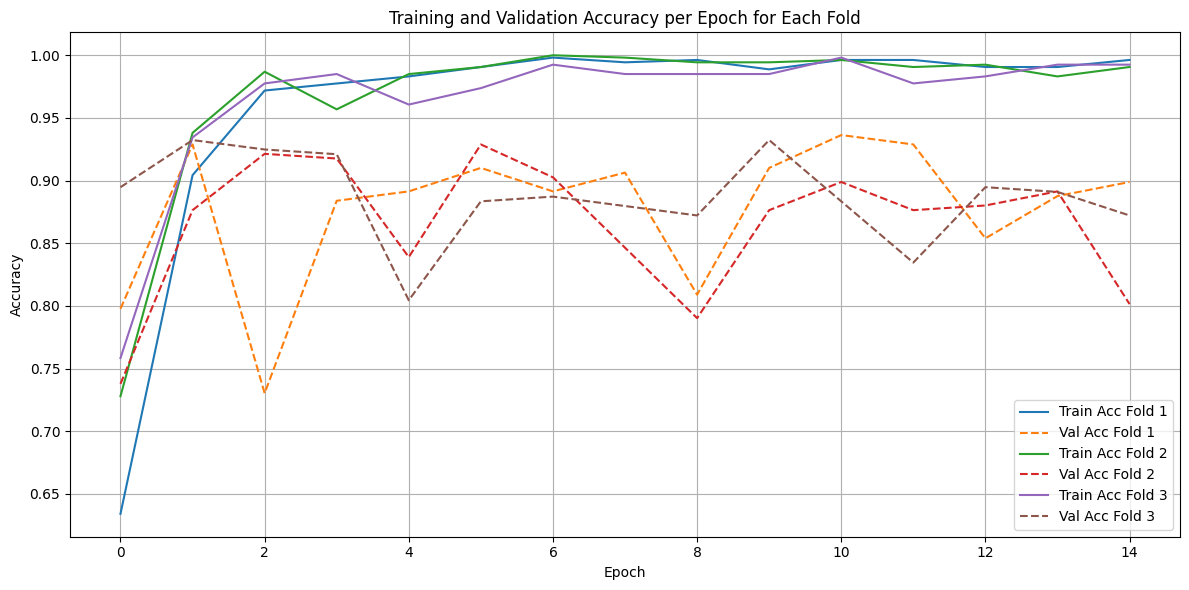

In [267]:
plot_acc(training_accuracies_per_folder, validation_accuracies_per_folder)

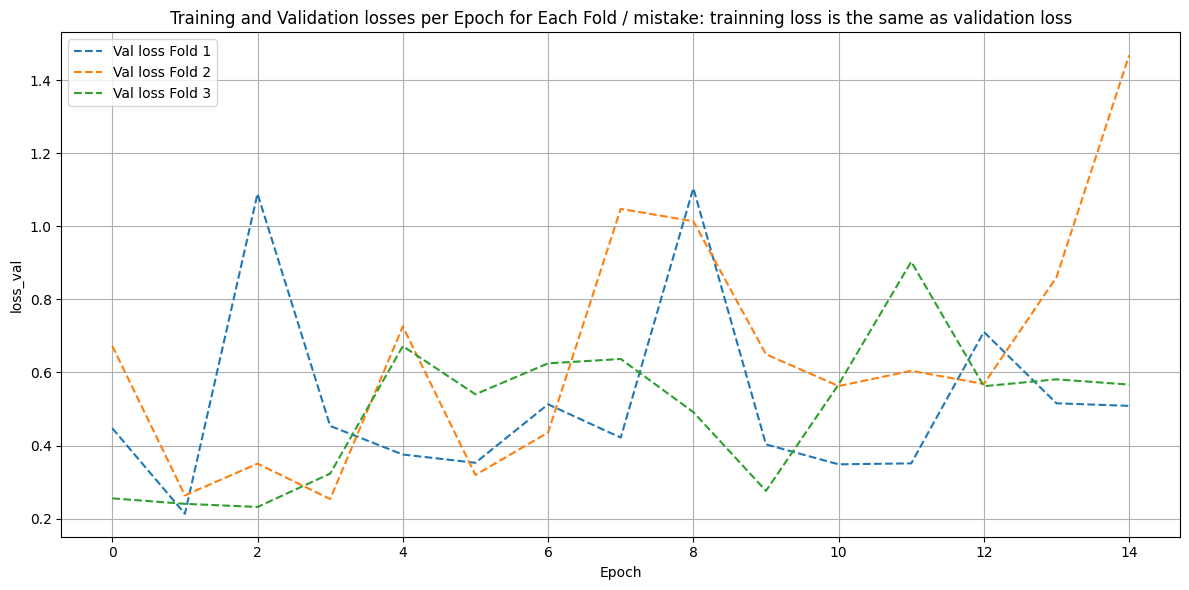

In [268]:
plot_loss(validation_losses_per_folder)

# train 2

Trainning specification: 

- dataset_size: 800 imagens
- 3 fold cross validation
- model: full trainning
- head replaced by smoth decrease
- normalization: (mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
- epochs: 15
- batch_size: 32
- learning_rate: 0.0001
- optimizer: Adam
- loss: CrossEntropyLoss
- trainning time: 70 mins 16 sec

In [269]:
(training_losses_per_folder, validation_losses_per_folder, 
training_accuracies_per_folder, validation_accuracies_per_folder, 
means, average_mean, description, train_time) = get_info(train_2)

Training losses per fold: {1: [0.6341463414634146, 0.9043151969981238, 0.9718574108818011, 0.9774859287054409, 0.9831144465290806, 0.9906191369606003, 0.99812382739212, 0.9943714821763602, 0.9962476547842402, 0.9887429643527205, 0.9962476547842402, 0.9962476547842402, 0.9906191369606003, 0.9906191369606003, 0.9962476547842402], 2: [0.7279549718574109, 0.9380863039399625, 0.9868667917448405, 0.9568480300187617, 0.9849906191369606, 0.9906191369606003, 1.0, 0.99812382739212, 0.9943714821763602, 0.9943714821763602, 0.9962476547842402, 0.9906191369606003, 0.9924953095684803, 0.9831144465290806, 0.9906191369606003], 3: [0.7584269662921348, 0.9344569288389513, 0.9775280898876404, 0.9850187265917603, 0.9606741573033708, 0.9737827715355806, 0.9925093632958801, 0.9850187265917603, 0.9850187265917603, 0.9850187265917603, 0.99812734082397, 0.9775280898876404, 0.9831460674157303, 0.9925093632958801, 0.9925093632958801]}
Validation losses per fold: {1: [0.44730116192544445, 0.21311971243847622, 1.08

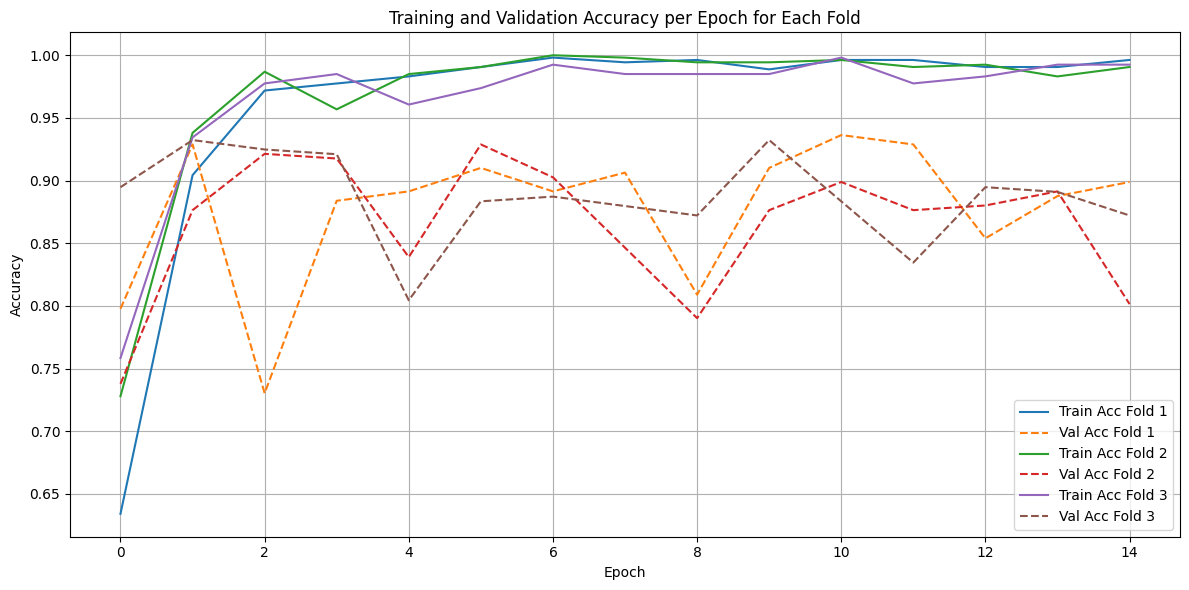

In [270]:
plot_acc(training_accuracies_per_folder, validation_accuracies_per_folder)

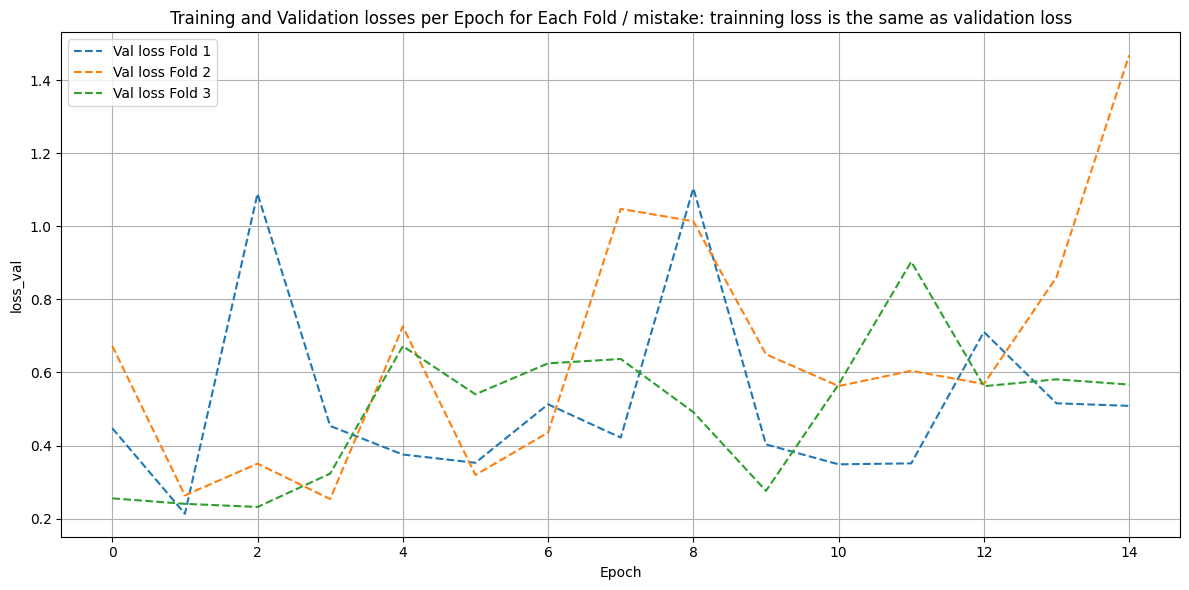

In [271]:
plot_loss(validation_losses_per_folder)

# train 3

Trainning specification: 

- dataset_size: 800 imagens
- 3 fold cross validation
- model: full tuning
- head replaced by smoth decrease
- normalization: (mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
- epochs: 15
- batch_size: 32
- learning_rate: One cycle
- optimizer: AdamW with weight decay
- loss: CrossEntropyLoss
- trainning time: 139 mins 16 sec

In [246]:
(training_losses_per_folder, validation_losses_per_folder, 
training_accuracies_per_folder, validation_accuracies_per_folder, 
means, average_mean, description, train_time) = get_info(train_3)

Training losses per fold: {1: [0.7166979362101313, 0.8968105065666041, 0.5684803001876173, 0.5703564727954972, 0.5234521575984991, 0.5384615384615384, 0.6303939962476548, 0.5928705440900562, 0.5290806754221389, 0.5440900562851783, 0.5984990619136961, 0.5928705440900562, 0.6360225140712945, 0.6660412757973734, 0.6829268292682927], 2: [0.7185741088180112, 0.8986866791744841, 0.6923076923076923, 0.5478424015009381, 0.5328330206378987, 0.474671669793621, 0.5084427767354597, 0.4915572232645403, 0.4878048780487805, 0.4821763602251407, 0.5065666041275797, 0.4878048780487805, 0.49906191369606, 0.5121951219512195, 0.50093808630394], 3: [0.7771535580524345, 0.8352059925093633, 0.6161048689138576, 0.5936329588014981, 0.5243445692883895, 0.6123595505617978, 0.5767790262172284, 0.6292134831460674, 0.6704119850187266, 0.7265917602996255, 0.7659176029962547, 0.8202247191011236, 0.8782771535580525, 0.9269662921348315, 0.949438202247191]}
Validation losses per fold: {1: [0.2883269850457652, 1.680348627

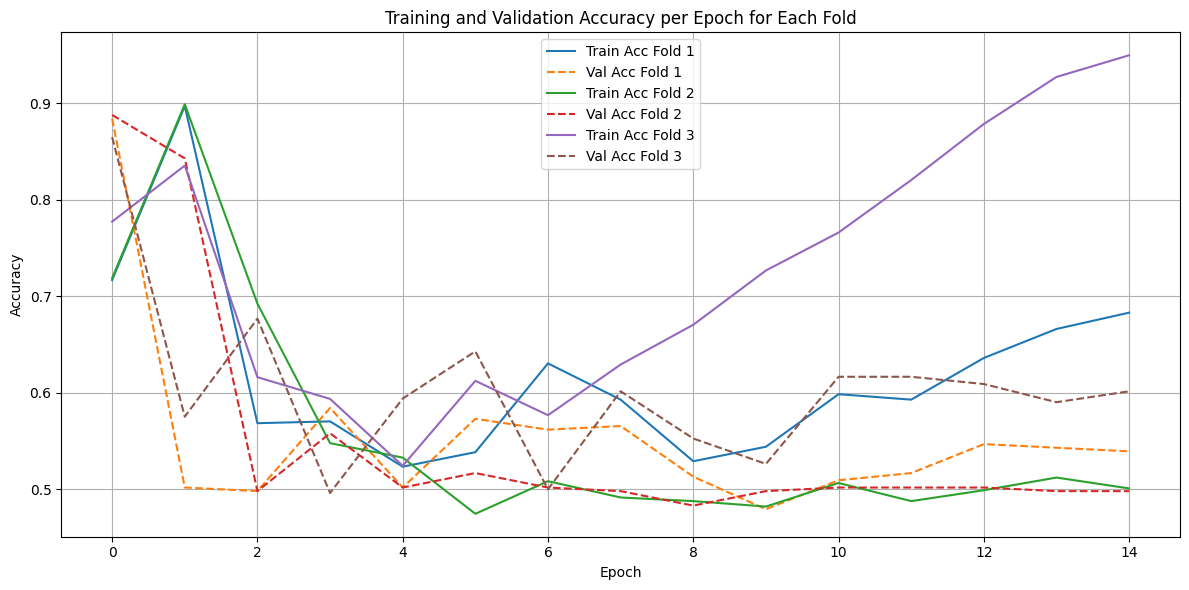

In [247]:
plot_acc(training_accuracies_per_folder, validation_accuracies_per_folder)

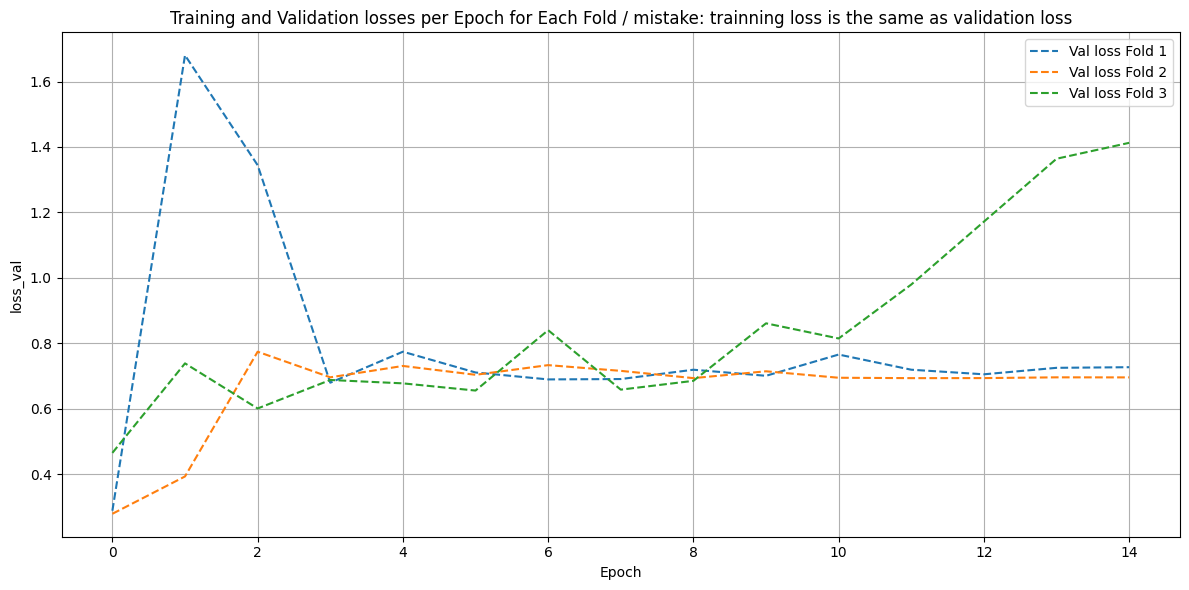

In [248]:
plot_loss(validation_losses_per_folder)

# train 4

Trainning specification: 

- dataset_size: 800 imagens
- 3 fold cross validation
- model: fine tuning
- head replace directly by 2 output head
- normalization: (mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
- epochs: 15
- batch_size: 32
- learning_rate:  0.0001 FIXED
- optimizer: AdamW with weight decay
- loss: CrossEntropyLoss
- trainning time: 25 mins 28 sec

In [249]:
(training_losses_per_folder, validation_losses_per_folder, 
training_accuracies_per_folder, validation_accuracies_per_folder, 
means, average_mean, description, train_time) = get_info(train_4)

Training losses per fold: {1: [0.6022514071294559, 0.701688555347092, 0.7223264540337712, 0.7523452157598499, 0.7861163227016885, 0.8048780487804879, 0.8198874296435272, 0.8273921200750469, 0.8405253283302064, 0.8461538461538461, 0.849906191369606, 0.8555347091932458, 0.8555347091932458, 0.8649155722326454, 0.8667917448405253], 2: [0.626641651031895, 0.7185741088180112, 0.7579737335834896, 0.7804878048780488, 0.8086303939962477, 0.8105065666041276, 0.8180112570356473, 0.8180112570356473, 0.8161350844277674, 0.8236397748592871, 0.8273921200750469, 0.8311444652908068, 0.8330206378986866, 0.8386491557223265, 0.8386491557223265], 3: [0.6704119850187266, 0.6966292134831461, 0.7097378277153558, 0.7415730337078652, 0.7602996254681648, 0.7883895131086143, 0.8014981273408239, 0.8239700374531835, 0.8239700374531835, 0.8258426966292135, 0.8333333333333334, 0.8370786516853933, 0.8389513108614233, 0.846441947565543, 0.8445692883895131]}
Validation losses per fold: {1: [0.6675947536243482, 0.6466068

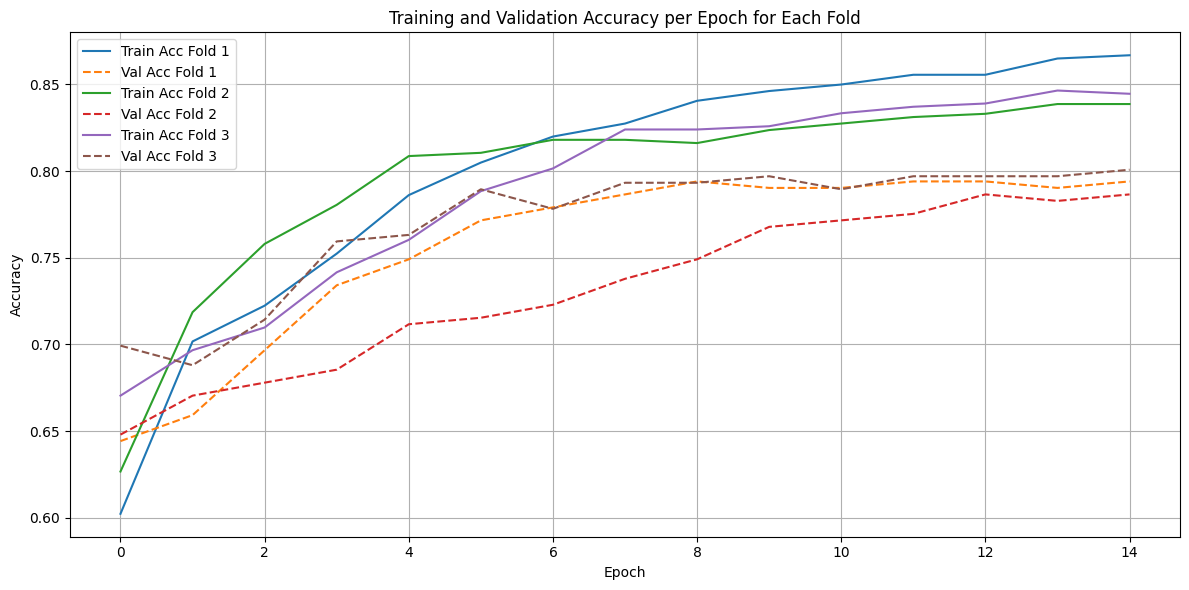

In [250]:
plot_acc(training_accuracies_per_folder, validation_accuracies_per_folder)

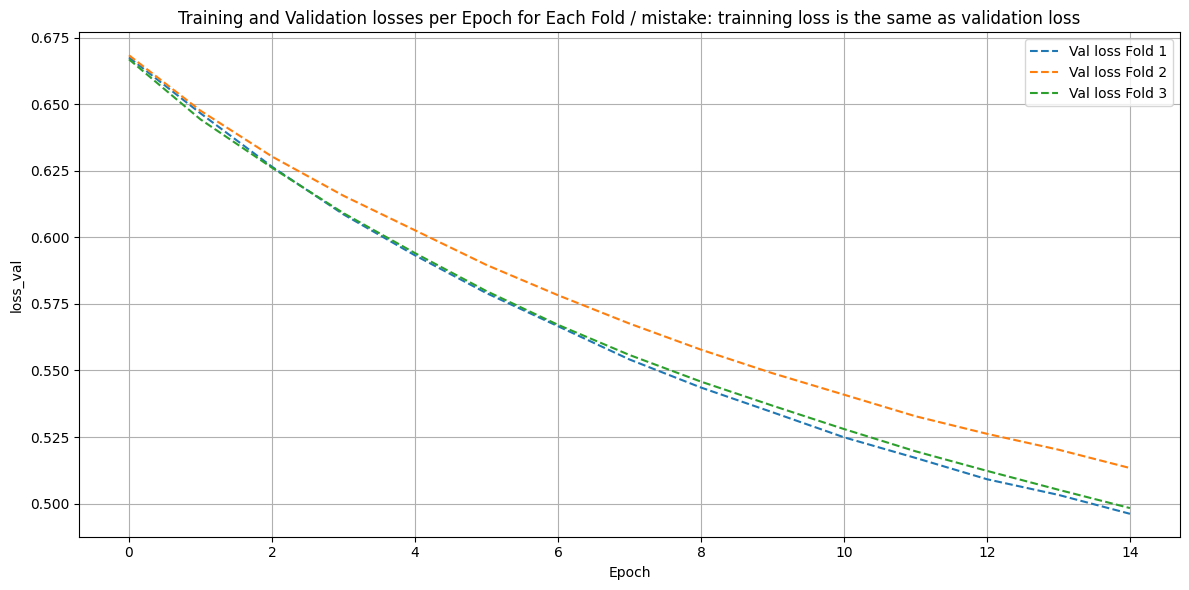

In [251]:
plot_loss(validation_losses_per_folder)

# train 5
Trainning specification: 

- dataset_size: 800 imagens
- 3 fold cross validation
- model: fine tuning
- head replace directly by 2 output head
- normalization: (mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
- epochs: 15
- batch_size: 32
- learning_rate:  0.00001 FIXED
- optimizer: AdamW with weight decay
- loss: CrossEntropyLoss
- trainning time: 25 mins 28 sec

In [252]:
(training_losses_per_folder, validation_losses_per_folder, 
training_accuracies_per_folder, validation_accuracies_per_folder, 
means, average_mean, description, train_time) = get_info(train_5)

Training losses per fold: {1: [0.6060037523452158, 0.6904315196998124, 0.699812382739212, 0.701688555347092, 0.7073170731707317, 0.7054409005628518, 0.7073170731707317, 0.7129455909943715, 0.7166979362101313, 0.7166979362101313, 0.7185741088180112, 0.7185741088180112, 0.7148217636022514, 0.7223264540337712, 0.7279549718574109], 2: [0.5534709193245778, 0.6716697936210131, 0.6829268292682927, 0.6923076923076923, 0.7073170731707317, 0.7091932457786116, 0.7148217636022514, 0.7223264540337712, 0.726078799249531, 0.7392120075046904, 0.7317073170731707, 0.7392120075046904, 0.7410881801125704, 0.7429643527204502, 0.7448405253283302], 3: [0.5561797752808989, 0.6460674157303371, 0.6573033707865169, 0.6629213483146067, 0.6722846441947565, 0.6741573033707865, 0.6741573033707865, 0.6797752808988764, 0.6835205992509363, 0.6872659176029963, 0.6910112359550562, 0.6928838951310862, 0.6985018726591761, 0.702247191011236, 0.702247191011236]}
Validation losses per fold: {1: [0.6904540229379461, 0.68771716

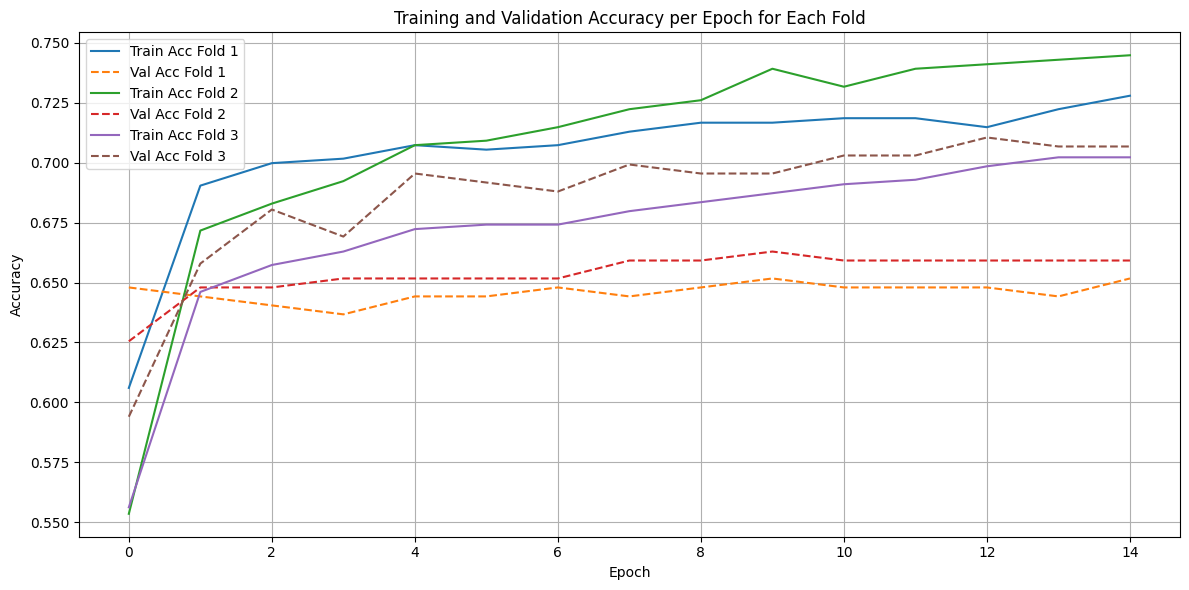

In [253]:
plot_acc(training_accuracies_per_folder, validation_accuracies_per_folder)

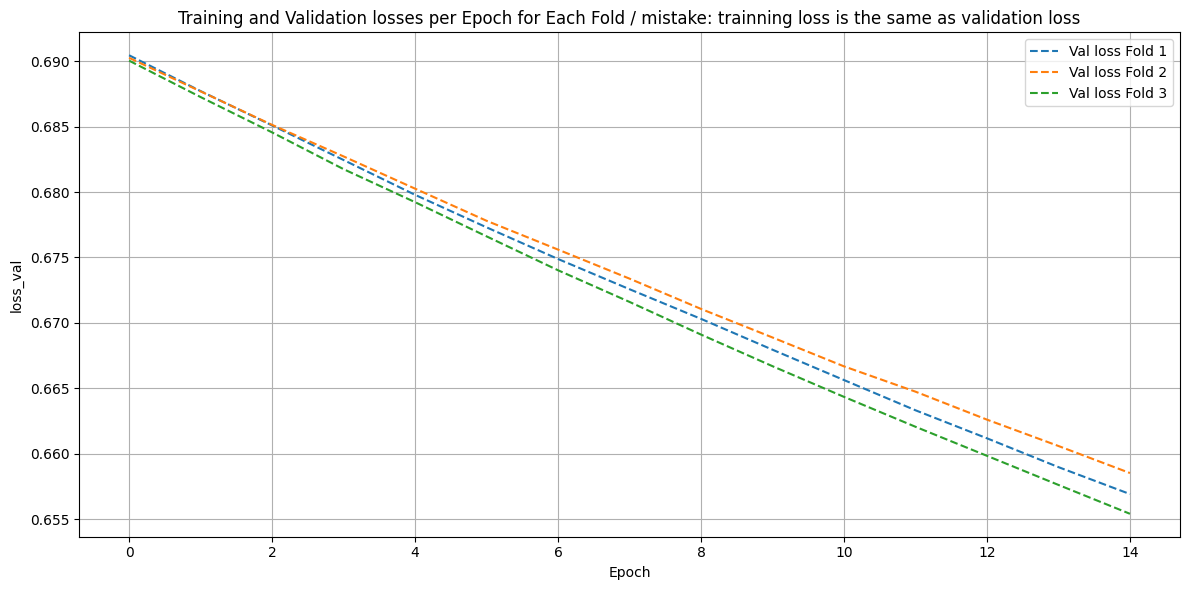

In [254]:
plot_loss(validation_losses_per_folder)

# train 6
Trainning specification: 

- dataset_size: 800 imagens
- 3 fold cross validation
- model: fine tuning
- head replace directly by 2 output head
- normalization: (mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
- epochs: 15
- batch_size: 32
- learning_rate:  0.001 FIXED
- optimizer: AdamW with weight decay
- loss: CrossEntropyLoss
- trainning time: 25 mins 28 sec

In [255]:
(training_losses_per_folder, validation_losses_per_folder, 
training_accuracies_per_folder, validation_accuracies_per_folder, 
means, average_mean, description, train_time) = get_info(train_6)

Training losses per fold: {1: [0.6315031609660465, 0.4765353065829787, 0.4045398595968286, 0.35417739060090586, 0.3180537465924841, 0.2889429681967615, 0.2641119415719782, 0.2455102996463847, 0.22565563059434657, 0.21155351417149657, 0.19678860712677632, 0.18689775047561688, 0.17474042351652935, 0.16494197631866356, 0.15574430689690932], 2: [0.6116293641908084, 0.46156082066094, 0.38732393569615275, 0.3422567524561068, 0.3057247363380375, 0.2748362172052516, 0.25026962387517065, 0.22878244986118115, 0.2122974441042537, 0.19626461215471014, 0.18384075318559248, 0.1706083369411626, 0.1598951254340542, 0.15139900762972197, 0.1427943848255204], 3: [0.6194728429844317, 0.4683331434199873, 0.39760458781924585, 0.3510172143857577, 0.31541810120536146, 0.2874631289015995, 0.2655388309379642, 0.24759878117716713, 0.22831360979026624, 0.21488626396164912, 0.2011025387249636, 0.19009729991021673, 0.17964694294590183, 0.16779250805074356, 0.16034694853123654]}
Validation losses per fold: {1: [0.52

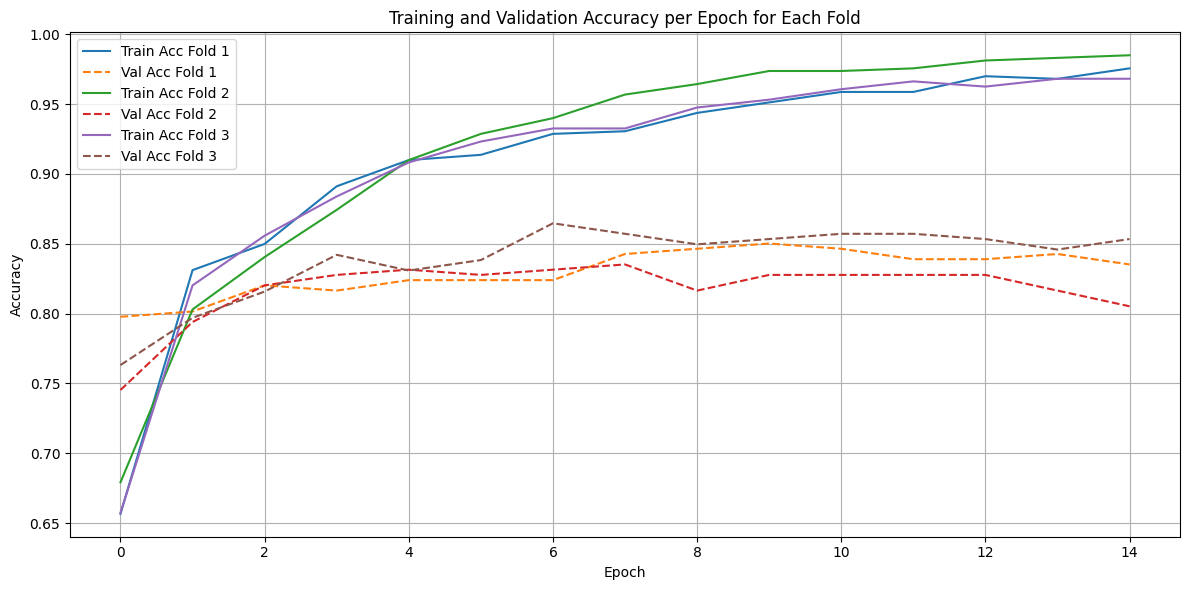

In [256]:
plot_acc(training_accuracies_per_folder, validation_accuracies_per_folder)

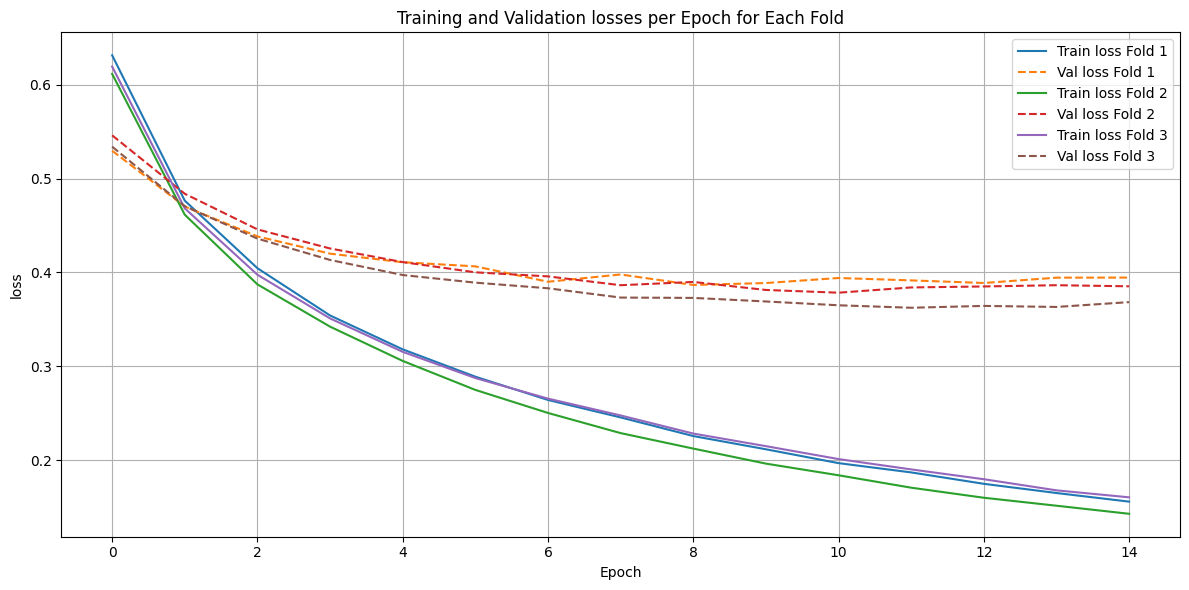

In [259]:
plot_all_loss(training_losses_per_folder, validation_losses_per_folder)